# 02 · Modelo de regresión: ¿cuántos días tardará en llegar un pedido?

**La pregunta:** cuando alguien hace una compra, ¿podemos estimar cuántos días va a tardar en llegarle el pedido?

Lo que queremos predecir es un número (`dias_entrega`), así que es un problema de **regresión**. Usamos los datos limpios del cuaderno 01: 89.713 pedidos entregados entre enero de 2017 y julio de 2018.

**¿Cómo vamos a saber si el modelo es bueno?** Con cuatro métricas:

- **MAE** (error absoluto medio): cuántos días se equivoca el modelo en promedio. Es nuestra métrica principal porque se entiende fácil: "el modelo se equivoca en promedio X días".
- **RMSE**: parecido al MAE, pero castiga más los errores grandes.
- **MAPE**: el error en porcentaje respecto de los días reales.
- **R²**: qué parte de la variación de los días logra explicar el modelo. Un 1 sería perfecto, y un 0 es lo mismo que responder siempre el promedio.

**Pasos que seguimos**

1. Elegimos las variables y separamos los datos por fecha en entrenamiento, validación y prueba.
2. Calculamos predicciones muy simples (*baselines*) para saber qué resultado hay que superar.
3. Probamos tres algoritmos y buscamos la mejor configuración de cada uno.
4. Elegimos el mejor con los datos de validación y lo medimos **una sola vez** con los datos de prueba.
5. Revisamos qué variables usa el modelo y lo guardamos para la aplicación.

**Cómo ejecutarlo:** igual que el cuaderno 01 (en Colab lee desde `Mi unidad/proyecto`). Primero hay que ejecutar el cuaderno 01. En el computador tarda unos 3 minutos; en Colab puede tardar 15–20 minutos.

In [1]:
# Importamos las librerías. De scikit-learn usamos los modelos, las métricas
# y las herramientas para preparar los datos y para buscar la mejor configuración.
import json
import sys
import time
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error, r2_score,
                             root_mean_squared_error)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# Si estamos en Colab, leemos los datos desde Google Drive; si no, desde la carpeta del proyecto
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/proyecto")  # cambiar si la carpeta está en otra ubicación de Drive
else:
    BASE = Path("..")

ARCHIVO = BASE / "data" / "processed" / "pedidos_entregados.csv"
MODELOS = BASE / "models"
if not ARCHIVO.exists():
    raise FileNotFoundError(f"No se encontró {ARCHIVO.resolve()}. Ejecuta primero el cuaderno 01.")
MODELOS.mkdir(exist_ok=True)
SEMILLA = 42  # fijamos la "semilla" del azar para que los resultados salgan iguales cada vez
print(f"scikit-learn {sklearn.__version__} · datos: {ARCHIVO.resolve()}")

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.3f}".format)

# Los mismos colores que en el cuaderno 01
SUPERFICIE, TINTA, TINTA_2, TENUE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRILLA, EJE = "#e1e0d9", "#c3c2b7"
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
RAMPA_AZUL = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": TINTA, "axes.titlecolor": TINTA, "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": TINTA_2, "axes.edgecolor": EJE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "xtick.color": EJE, "ytick.color": EJE, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": cycler(color=[AZUL, NARANJA, AQUA]),
})

scikit-learn 1.9.1 · datos: D:\Buri\proyecto\data\processed\pedidos_entregados.csv


In [2]:
# Cargamos los pedidos limpios y los ordenamos por fecha de compra
df = pd.read_csv(ARCHIVO, parse_dates=["order_purchase_timestamp", "order_estimated_delivery_date",
                                       "order_delivered_customer_date"])
df = df.sort_values("order_purchase_timestamp").reset_index(drop=True)
print(f"{len(df)} pedidos, {df.shape[1]} columnas")

89713 pedidos, 26 columnas


## 1. ¿Qué variables usamos para predecir?

Solo usamos variables que se conocen **en el momento de la compra**. Si usáramos, por ejemplo, la fecha en que el pedido salió con el transportista, el modelo funcionaría bien en el cuaderno pero no serviría en la vida real, porque al momento de comprar ese dato todavía no existe.

| Tipo | Variables | ¿Qué información dan? |
|---|---|---|
| Categorías | estado del cliente y del vendedor, categoría del producto, forma de pago y día de la semana | dónde, qué y cómo se compró |
| Números | distancia, si están en el mismo estado, días prometidos, flete, precio, peso, volumen, cantidad de productos, cantidad de vendedores, cuotas y hora | qué tan lejos va y qué tan grande es el pedido |

- Tratamos el **día de la semana** como categoría y no como número, porque el sábado no es "6 veces" el lunes: cada día tiene su propio comportamiento.
- **No usamos el mes.** En el cuaderno 01 vimos que en algunos meses pasaron cosas puntuales, como el Black Friday de 2017 o los retrasos de febrero y marzo de 2018. Con solo un año y medio de datos, el modelo podría aprender esos eventos como si se repitieran todos los años. En la sección 6 lo comprobamos.

In [3]:
# Separamos las variables para predecir (X) y lo que queremos predecir (y)
CATEGORICAS = ["customer_state", "seller_state", "categoria", "tipo_pago", "dia_semana"]
NUMERICAS = ["distancia_km", "mismo_estado", "dias_prometidos", "flete_total", "precio_total",
             "peso_total_g", "volumen_total_cm3", "n_items", "n_vendedores", "cuotas", "hora"]
OBJETIVO = "dias_entrega"
X = df[CATEGORICAS + NUMERICAS]
y = df[OBJETIVO]

# ¿Influye la forma de pago? Comparamos la mediana de días según cómo se pagó
print("Mediana de días de entrega por forma de pago:")
df.groupby("tipo_pago")[OBJETIVO].agg(["median", "size"]).rename(columns={"median": "mediana de días", "size": "pedidos"})

Mediana de días de entrega por forma de pago:


,mediana de días,pedidos
tipo_pago,,
boleto,11.809,18016
credit_card,10.271,67670
debit_card,9.219,1208
voucher,10.548,2819


**¿Qué vemos?** Sí influye. Cuando se paga con *boleto* (un comprobante que se paga en efectivo en un banco o una tienda y que tarda unos días en confirmarse), la mediana es de 11,8 días, contra 10,3 con tarjeta de crédito. Por eso incluimos la forma de pago.

## 2. Separamos los datos por fecha

No mezclamos los pedidos al azar: los separamos **por fecha de compra**, para simular cómo se usaría el modelo en la realidad. El modelo aprende con pedidos del pasado y se pone a prueba con pedidos posteriores que nunca vio.

| Conjunto | Pedidos comprados entre… | ¿Para qué lo usamos? |
|---|---|---|
| Entrenamiento | enero de 2017 y febrero de 2018 | para que los modelos aprendan y para elegir su configuración |
| Validación | marzo y abril de 2018 | para comparar los modelos y elegir el mejor |
| Prueba | mayo y julio de 2018 | para medir el modelo final **una sola vez**, al final |

La prueba se usa una sola vez porque, si la miráramos varias veces e hiciéramos cambios según el resultado, ya no estaríamos probando con datos "nuevos" para el modelo.

In [4]:
# Separamos los pedidos según su fecha de compra y vemos cuántos quedan en cada conjunto
fecha = df["order_purchase_timestamp"]
mascaras = {
    "entrenamiento": fecha < pd.Timestamp("2018-03-01"),
    "validación": (fecha >= pd.Timestamp("2018-03-01")) & (fecha < pd.Timestamp("2018-05-01")),
    "prueba": fecha >= pd.Timestamp("2018-05-01"),
}
X_ent, y_ent = X[mascaras["entrenamiento"]], y[mascaras["entrenamiento"]]
X_val, y_val = X[mascaras["validación"]], y[mascaras["validación"]]
X_pru, y_pru = X[mascaras["prueba"]], y[mascaras["prueba"]]

pd.DataFrame({
    nombre: {"pedidos": int(m.sum()), "% del total": 100 * m.mean(),
             "desde": fecha[m].min().date(), "hasta": fecha[m].max().date(),
             "mediana de días": y[m].median(), "promedio de días": y[m].mean()}
    for nombre, m in mascaras.items()
}).T

,pedidos,% del total,desde,hasta,mediana de días,promedio de días
entrenamiento,57031,63.570,2017-01-05,2018-02-28,11.356,13.609
validación,13794,15.376,2018-03-01,2018-04-30,11.116,13.940
prueba,18888,21.054,2018-05-01,2018-07-31,8.086,9.935


**¿Qué vemos?** Quedan el 64% de los pedidos para entrenar, el 15% para validar y el 21% para probar. Algo importante: **en el período de prueba las entregas fueron más rápidas**, con una mediana de 8,1 días, contra 11,4 en entrenamiento y 11,1 en validación. Ya lo habíamos visto en el cuaderno 01, y va a afectar los resultados de la prueba.

## 3. ¿Qué resultado hay que superar? (*baselines*)

Antes de entrenar modelos calculamos "predicciones" muy simples. Si nuestro modelo no las supera, no vale la pena usarlo:

- **Mediana global:** responder siempre la mediana de días del entrenamiento, sin mirar el pedido.
- **Mediana por estado:** responder la mediana de días del estado del cliente. Solo usa la ubicación.
- **Fecha prometida por Olist:** usar como predicción los días que promete Olist.

In [5]:
# Función que calcula las cuatro métricas
def metricas(y_real, y_pred):
    return {"MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": root_mean_squared_error(y_real, y_pred),
            "MAPE (%)": 100 * mean_absolute_percentage_error(y_real, y_pred),
            "R²": r2_score(y_real, y_pred)}


# Los baselines se calculan solo con los datos de entrenamiento, para no hacer trampa
def crear_baselines(X_ajuste, y_ajuste):
    """Baselines calculados solo con los datos de ajuste (entrenamiento, o entrenamiento + validación)."""
    mediana = y_ajuste.median()
    por_estado = y_ajuste.groupby(X_ajuste["customer_state"]).median()
    return {
        "Mediana global": lambda Xc: np.full(len(Xc), mediana),
        "Mediana por estado": lambda Xc: Xc["customer_state"].map(por_estado).fillna(mediana).to_numpy(),
        "Fecha prometida (Olist)": lambda Xc: Xc["dias_prometidos"].to_numpy(),
    }


# Métricas de los baselines en entrenamiento y en validación
baselines = crear_baselines(X_ent, y_ent)
filas = []
for nombre, predecir in baselines.items():
    for conjunto, (Xc, yc) in {"entrenamiento": (X_ent, y_ent), "validación": (X_val, y_val)}.items():
        filas.append({"modelo": nombre, "conjunto": conjunto, **metricas(yc, predecir(Xc))})
pd.DataFrame(filas).set_index(["modelo", "conjunto"])

MAE   RMSE  MAPE (%)     R²
modelo                  conjunto                                    
Mediana global          entrenamiento  6.311 10.329    62.233 -0.050
                        validación     7.243 10.717    75.225 -0.062
Mediana por estado      entrenamiento  5.529  9.493    50.295  0.113
                        validación     6.129  9.514    57.163  0.163
Fecha prometida (Olist) entrenamiento 12.944 15.199   153.507 -1.273
                        validación    11.479 13.519   146.611 -0.690

**¿Qué vemos?**

- La **mediana por estado** es la más difícil de superar: en validación se equivoca 6,13 días en promedio, contra 7,24 de la mediana global. Solo saber a qué estado va el pedido ya ayuda bastante.
- La **fecha prometida por Olist** es la peor (11,5 días de error), porque Olist promete con mucho margen a propósito.
- Un R² negativo significa que esa predicción es peor que responder siempre el promedio.

**Nuestra meta:** que el modelo se equivoque menos de **6,13 días** en validación.

## 4. ¿Cómo preparamos los datos para el modelo?

Los modelos solo entienden números y no aceptan datos vacíos, así que antes hay que preparar los datos. Pusimos todos estos pasos dentro de un **Pipeline** de scikit-learn, que funciona como una "receta": guarda los pasos de preparación junto con el modelo. Esto tiene dos ventajas:

- Los valores que se usan para preparar los datos (por ejemplo, la mediana para rellenar vacíos) se calculan **solo con los datos de entrenamiento**. Así evitamos la fuga de datos.
- Cuando guardamos el modelo, la receta se guarda con él, y la aplicación prepara los datos nuevos **exactamente igual** que en el entrenamiento.

| Paso | Ridge y Random Forest | Gradient Boosting |
|---|---|---|
| Números vacíos (distancia y cuotas) | se rellenan con la mediana del entrenamiento | el modelo sabe manejarlos solo |
| Categorías vacías (forma de pago, en 1 pedido) | se rellenan con la categoría más común | igual |
| Escala de los números | se ponen todos en la misma escala, para que ninguna variable pese más solo por tener números más grandes (Ridge lo necesita) | no hace falta |
| Categorías (SP, RJ…) | *one-hot encoding*: una columna de 0 y 1 por cada categoría | se convierten en códigos y el modelo las maneja directamente |
| Una categoría nueva que no estaba en el entrenamiento | se ignora | se trata como "desconocida" |

Además, como los días tienen la cola larga que vimos en el cuaderno 01, el modelo aprende con el **logaritmo** de los días y después convierte la predicción de vuelta a días. En la sección 6 comprobamos si esto realmente ayuda.

In [6]:
# Receta de preparación para Ridge y Random Forest
def prep_onehot(categoricas, numericas):
    """Rellena vacíos, convierte las categorías en columnas de 0 y 1 y pone los números en la misma escala."""
    return ColumnTransformer([
        ("categoricas", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")),
         categoricas),
        ("numericas", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numericas),
    ])


# Receta de preparación para Gradient Boosting
def prep_ordinal(categoricas, numericas):
    """Rellena vacíos en las categorías y las convierte en códigos; los números pasan tal cual."""
    return ColumnTransformer([
        ("categoricas", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                      OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)),
         categoricas),
        ("numericas", "passthrough", numericas),
    ])


# Envoltorio que entrena con log(1 + días) y devuelve las predicciones en días
def con_log(pipeline):
    """Entrena con log(1 + días) y devuelve las predicciones en días."""
    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1, check_inverse=False)

## 5. Probamos tres algoritmos

Elegimos tres algoritmos que funcionan de forma muy distinta, para ver cuál se adapta mejor a nuestros datos:

| Algoritmo | ¿Cómo funciona? | ¿Por qué lo elegimos? |
|---|---|---|
| **Ridge** | Una regresión lineal (como una "recta", pero con muchas variables) con regularización, que evita que el modelo le dé demasiado peso a una sola variable | Es simple y fácil de interpretar. La regularización ayuda porque varias de nuestras variables están relacionadas entre sí |
| **Random Forest** | Entrena muchos árboles de decisión, cada uno con una parte distinta de los datos, y promedia sus respuestas | Puede captar relaciones que no son rectas, como la curva de la distancia que vimos en el cuaderno 01 |
| **Gradient Boosting** | Entrena árboles uno detrás de otro; cada árbol nuevo intenta corregir los errores de los anteriores | Suele ser de los más precisos con datos en tablas, y es rápido |

**¿Qué son los hiperparámetros?** Son las "perillas" de cada algoritmo que hay que fijar antes de entrenar, como la profundidad de los árboles. Probamos estas opciones:

| Algoritmo | Hiperparámetros que probamos |
|---|---|
| Ridge | `alpha` (cuánta regularización): 0,1 · 1 · 10 · 100 |
| Random Forest | `max_depth` (profundidad máxima de los árboles): 10 · 16 · 24. `min_samples_leaf` (pedidos mínimos en cada hoja del árbol): 5 · 20. `max_features` (parte de las variables que mira cada división): 0,3 · 0,6 |
| Gradient Boosting | `learning_rate` (qué tan rápido aprende): 0,03 · 0,1. `max_leaf_nodes` (tamaño de cada árbol): 15 · 31 · 63. `min_samples_leaf`: 20 · 100. `l2_regularization` (un freno contra el sobreajuste): 0 · 1 |

**¿Cómo elegimos la mejor combinación?**

- En Ridge probamos todos los valores (*búsqueda en malla* o *grid search*).
- En Random Forest y Gradient Boosting hay demasiadas combinaciones, así que probamos 6 y 10 elegidas al azar (*búsqueda aleatoria* o *random search*).
- Cada combinación se evalúa con **validación cruzada temporal**: el modelo entrena con los meses más antiguos del entrenamiento y se evalúa con el bloque de meses que sigue. Esto se repite 4 veces, cada vez con más meses para entrenar. Así nunca usamos el futuro para predecir el pasado.
- Nos quedamos con la combinación que tiene el menor MAE.

In [7]:
# Validación cruzada temporal: 4 rondas, entrenando siempre con el pasado y validando con lo que sigue
cv_temporal = TimeSeriesSplit(n_splits=4)


# Para cada algoritmo: su receta, los hiperparámetros a probar y cuántas combinaciones probar
def crear_candidatos(categoricas, numericas):
    """Cada algoritmo con su pipeline, su espacio de hiperparámetros y el número de combinaciones a probar."""
    return {
        "Ridge": (
            con_log(Pipeline([("prep", prep_onehot(categoricas, numericas)), ("modelo", Ridge())])),
            {"regressor__modelo__alpha": [0.1, 1, 10, 100]},
            None,  # búsqueda en malla completa
        ),
        "Random Forest": (
            con_log(Pipeline([("prep", prep_onehot(categoricas, numericas)),
                              ("modelo", RandomForestRegressor(n_estimators=150, max_samples=0.5, n_jobs=-1,
                                                               random_state=SEMILLA))])),
            {"regressor__modelo__max_depth": [10, 16, 24],
             "regressor__modelo__min_samples_leaf": [5, 20],
             "regressor__modelo__max_features": [0.3, 0.6]},
            6,
        ),
        "Gradient Boosting": (
            con_log(Pipeline([("prep", prep_ordinal(categoricas, numericas)),
                              ("modelo", HistGradientBoostingRegressor(categorical_features=list(range(len(categoricas))),
                                                                       max_iter=500, early_stopping=True,
                                                                       random_state=SEMILLA))])),
            {"regressor__modelo__learning_rate": [0.03, 0.1],
             "regressor__modelo__max_leaf_nodes": [15, 31, 63],
             "regressor__modelo__min_samples_leaf": [20, 100],
             "regressor__modelo__l2_regularization": [0.0, 1.0]},
            10,
        ),
    }


# Buscamos la mejor configuración de cada algoritmo (esta es la celda que más tarda)
busquedas = {}
for nombre, (modelo, grilla, n_iter) in crear_candidatos(CATEGORICAS, NUMERICAS).items():
    inicio = time.time()
    if n_iter is None:
        busqueda = GridSearchCV(modelo, grilla, cv=cv_temporal, scoring="neg_mean_absolute_error",
                                return_train_score=True)
    else:
        busqueda = RandomizedSearchCV(modelo, grilla, n_iter=n_iter, cv=cv_temporal, scoring="neg_mean_absolute_error",
                                      return_train_score=True, random_state=SEMILLA)
    busqueda.fit(X_ent, y_ent)
    busquedas[nombre] = busqueda
    mejores = {k.replace("regressor__modelo__", ""): v for k, v in busqueda.best_params_.items()}
    print(f"{nombre}: MAE en validación cruzada = {-busqueda.best_score_:.2f} días "
          f"({time.time() - inicio:.0f} s) · mejor configuración: {mejores}")

Ridge: MAE en validación cruzada = 5.27 días (6 s) · mejor configuración: {'alpha': 100}


Random Forest: MAE en validación cruzada = 5.20 días (97 s) · mejor configuración: {'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 24}


Gradient Boosting: MAE en validación cruzada = 5.18 días (43 s) · mejor configuración: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'learning_rate': 0.03, 'l2_regularization': 1.0}


### Resultados de la búsqueda

Para cada combinación vemos el MAE promedio con los datos con que entrenó y con los datos con que se validó. Si el error de entrenamiento es mucho más bajo que el de validación, el modelo está **memorizando** los datos en vez de aprender patrones generales. A eso se le llama **sobreajuste**.

In [8]:
# Tabla con todas las combinaciones probadas, ordenadas de mejor a peor
def tabla_cv(busqueda):
    r = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in r.columns if c.startswith("param_")]
    t = r[params + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].copy()
    t.columns = ([c.replace("param_regressor__modelo__", "") for c in params]
                 + ["MAE entrenamiento", "MAE validación", "desviación", "ranking"])
    t[["MAE entrenamiento", "MAE validación"]] *= -1
    return t.sort_values("ranking").set_index("ranking")


for nombre, busqueda in busquedas.items():
    print(f"\n{nombre}")
    display(tabla_cv(busqueda))


Ridge


,alpha,MAE entrenamiento,MAE validación,desviación
ranking,,,,
1,100.000,4.557,5.271,1.211
2,10.000,4.547,5.277,1.203
3,1.000,4.544,5.282,1.199
4,0.100,4.544,5.284,1.198



Random Forest


,min_samples_leaf,max_features,max_depth,MAE entrenamiento,MAE validación,desviación
ranking,,,,,,
1,5,0.300,24,3.809,5.197,1.224
2,5,0.600,24,3.680,5.204,1.214
3,20,0.300,24,4.296,5.218,1.227
4,20,0.300,16,4.316,5.218,1.228
5,5,0.600,10,4.271,5.224,1.228
6,5,0.300,10,4.328,5.229,1.240



Gradient Boosting


,min_samples_leaf,max_leaf_nodes,learning_rate,l2_regularization,MAE entrenamiento,MAE validación,desviación
ranking,,,,,,,
1,100,15,0.030,1.000,4.284,5.183,1.216
2,100,31,0.100,0.000,4.124,5.183,1.196
3,100,15,0.030,0.000,4.287,5.184,1.213
4,20,15,0.030,0.000,4.255,5.187,1.213
5,20,15,0.100,1.000,4.263,5.188,1.212
6,100,63,0.030,0.000,4.065,5.193,1.199
7,100,31,0.100,1.000,4.137,5.194,1.198
8,20,63,0.030,1.000,3.982,5.196,1.198
9,20,31,0.100,0.000,4.136,5.196,1.204


**¿Qué vemos?**

- Los tres algoritmos quedan muy parejos: 5,27 días de error con Ridge, 5,20 con Random Forest y 5,18 con Gradient Boosting. Cambiar los hiperparámetros mueve muy poco el resultado.
- La columna **desviación** es alta (cerca de 1,2 días): el error cambia bastante según qué meses toque validar. Es otra señal de que las entregas cambian con el tiempo.
- **Ridge** funciona mejor con la regularización más fuerte (`alpha` = 100), lo que tiene sentido porque varias variables están relacionadas entre sí.
- **Random Forest** tiene un error de entrenamiento mucho más bajo que el de validación (3,8 contra 5,2): con árboles muy profundos, memoriza parte de los datos. Es un caso de **sobreajuste**.
- **Gradient Boosting** funciona mejor con una configuración "prudente": árboles pequeños, aprendizaje lento y al menos 100 pedidos por hoja. Así la diferencia entre entrenamiento (4,3) y validación (5,2) es menor.

## 6. Comparamos los modelos con los datos de validación

Ahora entrenamos cada algoritmo con su mejor configuración usando todo el entrenamiento, y lo evaluamos con los datos de validación (marzo y abril de 2018), junto con los baselines.

In [9]:
# Métricas de los baselines y de los tres modelos en entrenamiento y en validación
filas = []
for nombre, predecir in baselines.items():
    for conjunto, (Xc, yc) in {"entrenamiento": (X_ent, y_ent), "validación": (X_val, y_val)}.items():
        filas.append({"modelo": nombre, "conjunto": conjunto, **metricas(yc, predecir(Xc))})
for nombre, busqueda in busquedas.items():
    for conjunto, (Xc, yc) in {"entrenamiento": (X_ent, y_ent), "validación": (X_val, y_val)}.items():
        filas.append({"modelo": nombre, "conjunto": conjunto, **metricas(yc, busqueda.predict(Xc))})
comparacion = pd.DataFrame(filas).set_index(["modelo", "conjunto"])
comparacion

MAE   RMSE  MAPE (%)     R²
modelo                  conjunto                                    
Mediana global          entrenamiento  6.311 10.329    62.233 -0.050
                        validación     7.243 10.717    75.225 -0.062
Mediana por estado      entrenamiento  5.529  9.493    50.295  0.113
                        validación     6.129  9.514    57.163  0.163
Fecha prometida (Olist) entrenamiento 12.944 15.199   153.507 -1.273
                        validación    11.479 13.519   146.611 -0.690
Ridge                   entrenamiento  5.169  9.112    43.641  0.183
                        validación     5.712  9.152    47.130  0.226
Random Forest           entrenamiento  4.308  8.151    33.976  0.346
                        validación     5.556  8.994    43.472  0.252
Gradient Boosting       entrenamiento  4.865  8.740    39.540  0.248
                        validación     5.525  8.923    43.246  0.264

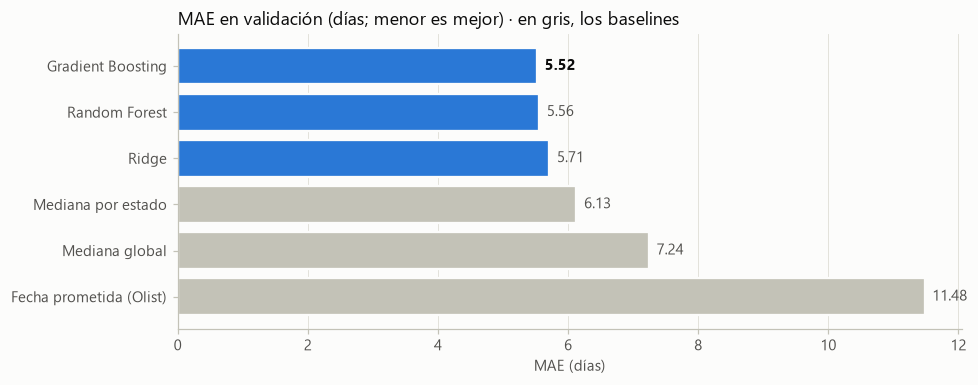

Mejor algoritmo en validación: Gradient Boosting


In [10]:
# Gráfico con el error en validación de cada modelo (en gris, los baselines)
mae_val = comparacion.xs("validación", level="conjunto")["MAE"].sort_values(ascending=False)
mejor_nombre = mae_val.loc[list(busquedas)].idxmin()
colores = [EJE if m in baselines else AZUL for m in mae_val.index]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(mae_val.index, mae_val.values, color=colores, edgecolor=SUPERFICIE, linewidth=1.5)
for i, (m, v) in enumerate(mae_val.items()):
    ax.annotate(f"{v:.2f}", xy=(v, i), xytext=(5, 0), textcoords="offset points", va="center",
                color=TINTA if m == mejor_nombre else TINTA_2, fontweight="bold" if m == mejor_nombre else "normal")
ax.set(title="MAE en validación (días; menor es mejor) · en gris, los baselines", xlabel="MAE (días)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"Mejor algoritmo en validación: {mejor_nombre}")

**¿Qué vemos?**

- Los tres modelos superan a todos los baselines. El mejor es **Gradient Boosting, que se equivoca 5,52 días en promedio**: un 10% menos que la mediana por estado (6,13) y un 24% menos que la mediana global (7,24).
- Random Forest queda casi empatado (5,56). Elegimos Gradient Boosting porque tiene un error un poco menor y porque el archivo del modelo pesa menos de 1 MB, mientras que el de Random Forest pesa unos 30 MB. Eso hace más liviana la aplicación.
- **Sobreajuste y subajuste** (comparando entrenamiento con validación):
  - **Ridge** tiene el error más alto incluso en entrenamiento (5,17). Como es un modelo lineal, no puede seguir curvas: le falta capacidad. Eso es **subajuste**.
  - **Random Forest** tiene la mayor diferencia (4,31 en entrenamiento contra 5,56 en validación): memoriza. Eso es **sobreajuste**.
  - **Gradient Boosting** queda en el medio (4,87 contra 5,53).
  - Ojo: parte de esa diferencia no es sobreajuste, sino que la validación es otro período, con otro comportamiento.
- El R² en validación es 0,26: el modelo explica cerca de una cuarta parte de por qué unos pedidos tardan más que otros.

### ¿Sirvió usar el logaritmo de los días?

Para comprobarlo, entrenamos el mismo modelo **sin** el logaritmo y comparamos.

In [11]:
# Mismo modelo y misma configuración, pero entrenado con los días sin transformar
sin_log = clone(busquedas[mejor_nombre].best_estimator_.regressor).fit(X_ent, y_ent)
pd.DataFrame({
    "con log1p": metricas(y_val, busquedas[mejor_nombre].predict(X_val)),
    "sin transformar": metricas(y_val, sin_log.predict(X_val)),
}).T

,MAE,RMSE,MAPE (%),R²
con log1p,5.525,8.923,43.246,0.264
sin transformar,5.646,8.625,51.643,0.312


**¿Qué vemos?** Con logaritmo, el MAE baja de 5,65 a 5,52 días y el MAPE de 51,6% a 43,2%, pero el RMSE y el R² empeoran un poco. Tiene una explicación: con logaritmo, el modelo apunta a un valor "típico" (parecido a la mediana) y no se deja arrastrar por los pedidos que tardaron muchísimo. Eso baja el error promedio (MAE). Pero cuando se equivoca en un pedido muy tardío el error es grande, y el RMSE castiga mucho esos errores grandes.

**¿Qué decidimos?** Como nuestra métrica principal es el MAE, **mantenemos el logaritmo**.

### ¿Y si agregamos el mes?

Probamos agregar el mes al modelo, con la misma configuración, para ver si ayudaba. También calculamos su **importancia por permutación**: desordenamos al azar la columna del mes y vemos cuánto cambia el error. Si el error sube, el modelo necesita esa variable; si baja, la variable le está haciendo daño.

In [12]:
# Entrenamos el mismo modelo agregando el mes y lo comparamos en validación
X_mes = df[CATEGORICAS + ["mes"] + NUMERICAS]
con_mes = crear_candidatos(CATEGORICAS + ["mes"], NUMERICAS)[mejor_nombre][0]
con_mes.set_params(**busquedas[mejor_nombre].best_params_)
con_mes.fit(X_mes[mascaras["entrenamiento"]], y_ent)
X_val_mes = X_mes[mascaras["validación"]]
muestra_val = X_val_mes.sample(5000, random_state=SEMILLA)
imp_mes = permutation_importance(con_mes, muestra_val, y_val.loc[muestra_val.index], scoring="neg_mean_absolute_error",
                                 n_repeats=5, random_state=SEMILLA)
print(f"MAE en validación sin mes: {mean_absolute_error(y_val, busquedas[mejor_nombre].predict(X_val)):.3f} días")
print(f"MAE en validación con mes: {mean_absolute_error(y_val, con_mes.predict(X_val_mes)):.3f} días")
print(f"Importancia por permutación del mes en validación: {imp_mes.importances_mean[muestra_val.columns.get_loc('mes')]:+.3f} días")

MAE en validación sin mes: 5.525 días
MAE en validación con mes: 5.859 días
Importancia por permutación del mes en validación: -0.240 días


**¿Qué vemos?** Con el mes, el error en validación **sube** de 5,52 a 5,86 días. Y al desordenar el mes, el error **baja** 0,24 días, o sea que el modelo funciona mejor sin esa información. El modelo estaba usando el mes para memorizar lo que pasó en meses específicos de 2017, y eso no se repitió en 2018.

**¿Qué decidimos?** **No usar el mes**, como habíamos pensado.

## 7. Modelo final: la prueba de verdad

Ya elegimos el algoritmo (Gradient Boosting) y su configuración. Ahora lo entrenamos con **entrenamiento + validación** (de enero de 2017 a abril de 2018) y lo evaluamos **una sola vez** con los datos de prueba (mayo a julio de 2018). Los baselines también se recalculan con esos mismos datos, para que la comparación sea justa.

In [13]:
# Entrenamos el modelo final y lo comparamos con los baselines en la prueba
X_ajuste, y_ajuste = pd.concat([X_ent, X_val]), pd.concat([y_ent, y_val])
modelo_final = clone(busquedas[mejor_nombre].best_estimator_).fit(X_ajuste, y_ajuste)
baselines_finales = crear_baselines(X_ajuste, y_ajuste)

filas = [{"modelo": f"{mejor_nombre} (final)", "conjunto": "entrenamiento + validación",
          **metricas(y_ajuste, modelo_final.predict(X_ajuste))},
         {"modelo": f"{mejor_nombre} (final)", "conjunto": "prueba", **metricas(y_pru, modelo_final.predict(X_pru))}]
filas += [{"modelo": nombre, "conjunto": "prueba", **metricas(y_pru, predecir(X_pru))}
          for nombre, predecir in baselines_finales.items()]
resultado_final = pd.DataFrame(filas).set_index(["modelo", "conjunto"])
resultado_final

MAE   RMSE  MAPE (%)  \
modelo                    conjunto                                             
Gradient Boosting (final) entrenamiento + validación  4.970  8.711    40.254   
                          prueba                      4.567  6.340    61.003   
Mediana global            prueba                      5.439  7.246    95.422   
Mediana por estado        prueba                      4.746  6.521    75.039   
Fecha prometida (Olist)   prueba                     14.167 16.536   213.223   

                                                         R²  
modelo                    conjunto                           
Gradient Boosting (final) entrenamiento + validación  0.263  
                          prueba                      0.206  
Mediana global            prueba                     -0.037  
Mediana por estado        prueba                      0.160  
Fecha prometida (Olist)   prueba                     -4.401

**¿Qué vemos?**

- En la prueba, el modelo se equivoca **4,57 días en promedio** y sigue siendo mejor que los tres baselines: la mediana por estado se equivoca 4,75 días, la mediana global 5,44 y la fecha de Olist 14,2.
- Pero la ventaja sobre la mediana por estado es menor que en validación: 4% en vez de 10%.
- Puede parecer raro que el error en la prueba (4,57) sea menor que en entrenamiento (4,97). Pasa porque en la prueba las entregas son más cortas y entonces los errores en días también lo son. En porcentaje, el error es mayor: el MAPE sube de 40% a 61% y el R² baja de 0,26 a 0,21.
- El MAPE se ve muy alto porque divide por los días reales: equivocarse 2 días en un pedido que tardó 3 cuenta como un 67% de error. Por eso no lo usamos como métrica principal.

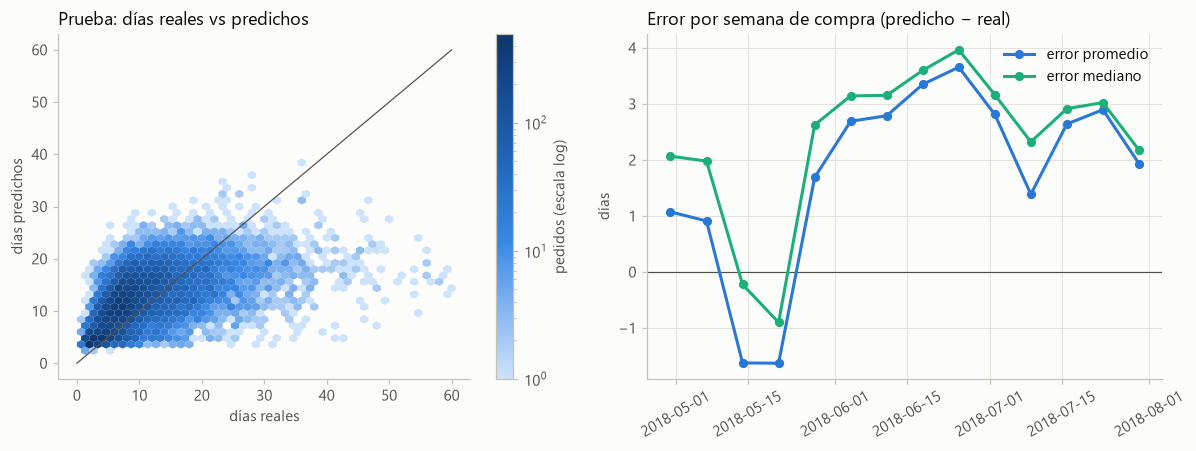

Error promedio en prueba: +1.76 días · pedidos con error de menos de 3 días: 42%


In [14]:
# A la izquierda: días reales contra días predichos. A la derecha: el error promedio de cada semana
pred_pru = modelo_final.predict(X_pru)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
hb = ax[0].hexbin(y_pru, pred_pru, gridsize=45, extent=(0, 60, 0, 60), bins="log", mincnt=1, cmap=RAMPA_AZUL,
                  linewidths=0)
ax[0].plot([0, 60], [0, 60], color=TINTA_2, linewidth=0.8)
fig.colorbar(hb, ax=ax[0], label="pedidos (escala log)")
ax[0].set(title="Prueba: días reales vs predichos", xlabel="días reales", ylabel="días predichos")
ax[0].grid(False)

errores = pd.DataFrame({"semana": df.loc[mascaras["prueba"], "order_purchase_timestamp"].dt.to_period("W").dt.start_time,
                        "error": pred_pru - y_pru.to_numpy()})
por_semana = errores.groupby("semana")["error"].agg(["mean", "median"])
ax[1].axhline(0, color=TINTA_2, linewidth=0.8)
ax[1].plot(por_semana.index, por_semana["mean"], marker="o", markersize=5, color=AZUL, label="error promedio")
ax[1].plot(por_semana.index, por_semana["median"], marker="o", markersize=5, color=AQUA, label="error mediano")
ax[1].set(title="Error por semana de compra (predicho − real)", ylabel="días")
ax[1].legend(loc="upper right")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print(f"Error promedio en prueba: {np.mean(pred_pru - y_pru):+.2f} días · "
      f"pedidos con error de menos de 3 días: {np.mean(np.abs(pred_pru - y_pru) < 3):.0%}")

**¿Qué vemos?**

- En promedio, el modelo **predice 1,8 días de más**. Mayo, junio y julio de 2018 fueron más rápidos que los meses con que entrenó (la mediana bajó de 11 a 8 días), y el modelo no tenía forma de saberlo.
- A mediados de mayo pasa lo contrario: el modelo **predice de menos**, porque los pedidos de esas semanas se atrasaron. Coincide con la huelga nacional de camioneros en Brasil (21 al 31 de mayo de 2018). Después, en junio y julio, vuelve a predecir entre 2 y 4 días de más.
- En el gráfico de la izquierda, si el modelo fuera perfecto todos los puntos estarían sobre la línea diagonal. Se ve que casi nunca predice más de 30 días, aunque algunos pedidos tardaron 40 o 50. Esos retrasos extremos dependen de cosas que no están en los datos.
- El 42% de los pedidos tiene un error de menos de 3 días.

## 8. ¿Qué variables usa más el modelo?

Usamos la **importancia por permutación**: desordenamos al azar una variable a la vez y medimos cuánto sube el error. Si sube mucho, el modelo depende de esa variable. Lo calculamos con 5.000 pedidos de prueba y repetimos 5 veces con cada variable.

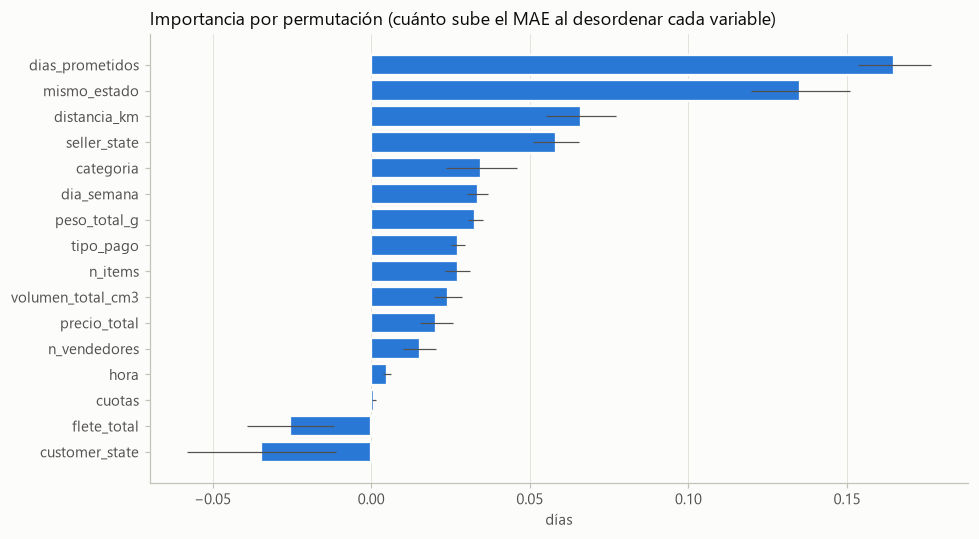

,aumento del MAE (días),desviación
dias_prometidos,0.165,0.011
mismo_estado,0.135,0.015
distancia_km,0.066,0.011
seller_state,0.058,0.007
categoria,0.035,0.011
dia_semana,0.034,0.003
peso_total_g,0.033,0.002
tipo_pago,0.027,0.002
n_items,0.027,0.004
volumen_total_cm3,0.024,0.004


In [15]:
# Importancia por permutación de cada variable en la prueba
muestra = X_pru.sample(5000, random_state=SEMILLA)
imp = permutation_importance(modelo_final, muestra, y_pru.loc[muestra.index], scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=SEMILLA, n_jobs=1)
importancia = (pd.DataFrame({"aumento del MAE (días)": imp.importances_mean, "desviación": imp.importances_std},
                            index=muestra.columns)
               .sort_values("aumento del MAE (días)"))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importancia.index, importancia["aumento del MAE (días)"], xerr=importancia["desviación"], color=AZUL,
        edgecolor=SUPERFICIE, linewidth=1.5, error_kw=dict(ecolor=TINTA_2, elinewidth=0.8))
ax.set(title="Importancia por permutación (cuánto sube el MAE al desordenar cada variable)", xlabel="días")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
importancia.sort_values("aumento del MAE (días)", ascending=False)

**¿Qué vemos?**

- Las variables más importantes son los **días prometidos**, si el vendedor y el cliente están en el **mismo estado** y la **distancia**. Las tres tienen que ver con qué tan lejos va el pedido, y los días prometidos además resumen lo que Olist sabe de cada ruta.
- Después vienen el estado del vendedor, la categoría, el día de la semana, el peso y la forma de pago, que aportan menos.
- El estado del cliente y el flete salen un poco negativos. Su información ya está en la distancia y en `mismo_estado`, y además los retrasos que hubo en algunos estados durante el entrenamiento no se repitieron igual en 2018.

**¿Por qué no las sacamos?** Porque esa decisión la estaríamos tomando mirando los resultados de la prueba, y la prueba solo sirve para medir, no para hacer cambios. Lo dejamos como una mejora para probar con los datos de validación.

### Un rango en vez de un solo número

Un solo número puede dar una idea falsa de exactitud. Por eso, además de la predicción, la aplicación va a mostrar un **rango probable**. Lo calculamos con los errores del modelo en la prueba: buscamos entre qué valores quedó el error del 80% de los pedidos (del percentil 10 al percentil 90).

In [16]:
# Errores en la prueba: días reales menos días predichos (negativo = el pedido llegó antes de lo estimado)
error_dias = y_pru.to_numpy() - pred_pru
p10, p90 = np.percentile(error_dias, [10, 90])
print(f"Error del 80% central de los pedidos de prueba: entre {p10:+.1f} y {p90:+.1f} días")
print(f"Pedidos de prueba dentro de ese rango: {np.mean((error_dias >= p10) & (error_dias <= p90)):.0%}")

Error del 80% central de los pedidos de prueba: entre -7.7 y +4.8 días
Pedidos de prueba dentro de ese rango: 80%


**¿Qué vemos?** En el 80% de los pedidos de prueba, el pedido llegó entre 7,7 días antes y 4,8 días después de lo que dijo el modelo. El rango no es simétrico porque, como vimos arriba, en la prueba el modelo tendía a predecir de más.

**¿Qué decidimos?** La aplicación muestra como rango probable desde la predicción menos 7,7 días hasta la predicción más 4,8 días. Por ejemplo, para un pedido estimado en 13,5 días, el rango va de 5,8 a 18,3 días.

## 9. Guardamos el modelo para la aplicación

Las métricas de la prueba son del modelo entrenado hasta abril de 2018. Para la aplicación, **volvemos a entrenarlo con todos los datos** (de enero de 2017 a julio de 2018) y la misma configuración. Así también aprende de los meses más recientes, que fueron más rápidos. Primero se evalúa con datos que el modelo no conoce y, cuando ya está elegido, se entrena con todo lo que hay.

Guardamos el modelo junto con su "receta" de preparación (el pipeline completo) usando `joblib`, más un archivo JSON con su descripción: qué variables necesita, su configuración, sus métricas y la versión de scikit-learn. **La aplicación tiene que usar la misma versión de scikit-learn** para poder abrir el modelo.

In [17]:
# Reentrenamos con todos los datos y guardamos el modelo y su descripción
modelo_app = clone(modelo_final).fit(X, y)
ruta_modelo = MODELOS / "regresion_dias_entrega.joblib"
joblib.dump(modelo_app, ruta_modelo, compress=3)

metricas_prueba = resultado_final.loc[(f"{mejor_nombre} (final)", "prueba")].round(4).to_dict()
metadatos = {
    "modelo": mejor_nombre,
    "objetivo": OBJETIVO,
    "unidad": "días",
    "transformacion_objetivo": "log1p / expm1",
    "categoricas": CATEGORICAS,
    "numericas": NUMERICAS,
    "hiperparametros": {k.replace("regressor__modelo__", ""): v for k, v in busquedas[mejor_nombre].best_params_.items()},
    "entrenado_con": "todas las compras de 2017-01-05 a 2018-07-31",
    "evaluacion": "modelo entrenado con compras hasta 2018-04-30 y evaluado con compras de mayo a julio de 2018",
    "metricas_prueba": metricas_prueba,
    "mae_baseline_mediana_prueba": round(float(resultado_final.loc[("Mediana global", "prueba"), "MAE"]), 4),
    "rango_error_dias": {"p10": round(float(p10), 2), "p90": round(float(p90), 2),
                         "explicacion": "rango probable = predicción + p10 hasta predicción + p90 (80% de los pedidos de prueba)"},
    "version_sklearn": sklearn.__version__,
    "fecha": date.today().isoformat(),
}
(MODELOS / "regresion_dias_entrega.json").write_text(json.dumps(metadatos, indent=2, ensure_ascii=False, default=str),
                                                     encoding="utf-8")
print(f"{ruta_modelo.name}: {ruta_modelo.stat().st_size / 1e6:.1f} MB")
print(json.dumps(metadatos, indent=2, ensure_ascii=False, default=str))

regresion_dias_entrega.joblib: 0.4 MB
{
  "modelo": "Gradient Boosting",
  "objetivo": "dias_entrega",
  "unidad": "días",
  "transformacion_objetivo": "log1p / expm1",
  "categoricas": [
    "customer_state",
    "seller_state",
    "categoria",
    "tipo_pago",
    "dia_semana"
  ],
  "numericas": [
    "distancia_km",
    "mismo_estado",
    "dias_prometidos",
    "flete_total",
    "precio_total",
    "peso_total_g",
    "volumen_total_cm3",
    "n_items",
    "n_vendedores",
    "cuotas",
    "hora"
  ],
  "hiperparametros": {
    "min_samples_leaf": 100,
    "max_leaf_nodes": 15,
    "learning_rate": 0.03,
    "l2_regularization": 1.0
  },
  "entrenado_con": "todas las compras de 2017-01-05 a 2018-07-31",
  "evaluacion": "modelo entrenado con compras hasta 2018-04-30 y evaluado con compras de mayo a julio de 2018",
  "metricas_prueba": {
    "MAE": 4.5668,
    "RMSE": 6.3402,
    "MAPE (%)": 61.0034,
    "R²": 0.206
  },
  "mae_baseline_mediana_prueba": 5.4386,
  "rango_error_dia

### Probamos el modelo guardado, como lo hará la aplicación

Abrimos el archivo guardado y le pedimos una predicción para un pedido inventado. La aplicación va a recibir estos mismos datos desde la página web.

In [18]:
# Comprobamos que el modelo guardado da las mismas predicciones que el que tenemos en memoria
modelo_cargado = joblib.load(ruta_modelo)
assert np.allclose(modelo_cargado.predict(X_pru), modelo_app.predict(X_pru)), "El modelo cargado no reproduce las predicciones"

# Un pedido de ejemplo: de un vendedor de São Paulo a un cliente de Río de Janeiro
pedido_nuevo = pd.DataFrame([{
    "customer_state": "RJ", "seller_state": "SP", "categoria": "bed_bath_table", "tipo_pago": "credit_card",
    "dia_semana": 2, "distancia_km": 360.0, "mismo_estado": 0, "dias_prometidos": 20.0,
    "flete_total": 18.5, "precio_total": 120.0, "peso_total_g": 1200, "volumen_total_cm3": 9000,
    "n_items": 1, "n_vendedores": 1, "cuotas": 3, "hora": 15,
}])
entradas = metadatos["categoricas"] + metadatos["numericas"]  # la aplicación toma el orden de las columnas del JSON
dias = modelo_cargado.predict(pedido_nuevo[entradas])[0]
rango = metadatos["rango_error_dias"]
print(f"Pedido de São Paulo a Río de Janeiro: {dias:.1f} días estimados "
      f"(rango probable: {max(0.5, dias + rango['p10']):.1f} a {dias + rango['p90']:.1f} días)")

Pedido de São Paulo a Río de Janeiro: 13.5 días estimados (rango probable: 5.8 a 18.3 días)


## 10. Conclusiones

**Resumen del modelo**

| | |
|---|---|
| Algoritmo elegido | Gradient Boosting, entrenado con el logaritmo de los días |
| Configuración final | `learning_rate` 0,03 · `max_leaf_nodes` 15 · `min_samples_leaf` 100 · `l2_regularization` 1 (hasta 500 árboles; se detiene antes si deja de mejorar) |
| Cómo la elegimos | búsqueda aleatoria de 10 combinaciones con validación cruzada temporal de 4 rondas, buscando el menor MAE |
| Error en validación (MAE) | 5,52 días (mediana por estado: 6,13) |
| Error en prueba (MAE) | 4,57 días (mediana por estado: 4,75; mediana global: 5,44) |
| R² en prueba | 0,21 |

**¿Qué significa?** Nuestro modelo predice mejor que todas las alternativas simples, y lo que más usa es la ubicación del pedido. Pero solo explica cerca de una cuarta parte de por qué unos pedidos tardan más que otros (R² entre 0,21 y 0,26). Aprendimos que el tiempo de entrega depende mucho de cosas que no están en los datos, como la empresa de transporte, si el vendedor tenía el producto, el clima o las huelgas.

**Limitaciones**

- **Las entregas cambian con el tiempo:** en la prueba el modelo predijo 1,8 días de más, porque a mediados de 2018 las entregas fueron más rápidas que antes.
- **Eventos inesperados:** la huelga de camioneros de mayo de 2018 atrasó pedidos, y ningún modelo entrenado con datos anteriores podía preverlo.
- **Retrasos extremos:** el modelo casi nunca predice más de 30 días.

**¿Cómo se podría mejorar?**

- Volver a entrenar el modelo cada cierto tiempo con los datos más nuevos (para la aplicación ya lo entrenamos con todos los datos hasta julio de 2018).
- Darles más peso a los pedidos recientes al entrenar, o agregar una variable con lo que tardaron las entregas de las últimas semanas.
- En vez de dar un solo número, dar un rango (por ejemplo, "entre 6 y 14 días"), usando regresión por cuantiles.

**Archivos para la aplicación:** `models/regresion_dias_entrega.joblib` (el modelo con su preparación de datos) y `models/regresion_dias_entrega.json` (su descripción).